In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
import time
import os

device = "cuda" if torch.cuda.is_available() else "cpu"
# macbook : "mps"
print(f"Using device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

if not os.path.exists("shakespeare.txt"):
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, "shakespeare.txt")

with open("shakespeare.txt") as f: 
    text = f.read()

print(f"Total characters: {len(text):,}")
print(f"First 200 characters:\n{text[:200]}")


Total characters: 1,115,394
First 200 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


## 2. Byte Pair Encoding (BPE) Tokenization

Instead of character-level tokenization (fixed vocabulary of ~65 individual characters),
**Byte Pair Encoding (BPE)** begins with character tokens and iteratively merges the most frequent
adjacent pairs of symbols into subword/word tokens.

### Key advantages for MiniLLM:
1. **Compression**: Sequences become ~1.65× shorter (each token covers ~1.65 characters on average).
2. **Effective Context Window**: With `max_seq_len = 256`, the model can see ~420 characters of text instead of just 256.
3. **Subword Semantics**: Frequent prefixes, suffixes, and common words (e.g., `'th'`, `'the'`, `'you'`, `'and'`) become single tokens.

In [3]:
# --- Byte Pair Encoding (BPE) Tokenizer ---
import re
from collections import Counter

# Split text into whitespace and word chunks (preserving whitespace)
words = re.findall(r"\S+|\s+", text)
word_counts = Counter(words)

# Base vocabulary: all unique characters + <unk> fallback
chars = sorted(set(text))
UNK_TOKEN = "<unk>"
base_tokens = [UNK_TOKEN] + chars

# Initial dictionary for BPE training: tuple of characters -> frequency
bpe_vocab = {tuple(w): count for w, count in word_counts.items()}

NUM_MERGES = 300  # Number of BPE merges to learn (adjust as desired: e.g. 300 - 500)

def get_pair_stats(vocab):
    pairs = Counter()
    for word_tuple, freq in vocab.items():
        for i in range(len(word_tuple) - 1):
            pairs[(word_tuple[i], word_tuple[i + 1])] += freq
    return pairs

def merge_vocab(pair, vocab):
    new_vocab = {}
    bigram = pair
    replacement = "".join(pair)
    for word_tuple, freq in vocab.items():
        new_tuple = []
        i = 0
        while i < len(word_tuple):
            if i < len(word_tuple) - 1 and (word_tuple[i], word_tuple[i + 1]) == bigram:
                new_tuple.append(replacement)
                i += 2
            else:
                new_tuple.append(word_tuple[i])
                i += 1
        new_vocab[tuple(new_tuple)] = freq
    return new_vocab

print(f"Training BPE with {NUM_MERGES} merges on TinyShakespeare...")
merges = {}
t0 = time.time()
for i in range(NUM_MERGES):
    pairs = get_pair_stats(bpe_vocab)
    if not pairs:
        break
    best_pair = max(pairs, key=pairs.get)
    bpe_vocab = merge_vocab(best_pair, bpe_vocab)
    merges[best_pair] = "".join(best_pair)
    if (i + 1) % 50 == 0 or i == 0:
        print(f"  Merge {i+1:3d}: {best_pair[0]!r} + {best_pair[1]!r} -> {merges[best_pair]!r} (freq: {pairs[best_pair]:,})")

print(f"BPE training complete in {time.time() - t0:.2f}s!")

# Build complete vocabulary mapping
token_list = base_tokens + [t for t in merges.values() if t not in base_tokens]
token_to_id = {tok: i for i, tok in enumerate(token_list)}
id_to_token = {i: tok for i, tok in enumerate(token_list)}
vocab_size = len(token_list)

# Fast cached word encoder
word_cache = {}

def encode_word(w):
    if w in word_cache:
        return word_cache[w]
    tokens = list(w)
    for pair, replacement in merges.items():
        if len(tokens) < 2:
            break
        i = 0
        new_tokens = []
        while i < len(tokens):
            if i < len(tokens) - 1 and (tokens[i], tokens[i + 1]) == pair:
                new_tokens.append(replacement)
                i += 2
            else:
                new_tokens.append(tokens[i])
                i += 1
        tokens = new_tokens
    unk_id = token_to_id[UNK_TOKEN]
    ids = [token_to_id.get(t, unk_id) for t in tokens]
    word_cache[w] = ids
    return ids

def encode(s):
    w_list = re.findall(r"\S+|\s+", s)
    out = []
    for w in w_list:
        out.extend(encode_word(w))
    return out

def decode(ids):
    return "".join(id_to_token.get(i, UNK_TOKEN) for i in ids)

print(f"\nVocabulary size: {vocab_size} ({len(base_tokens)} base + {len(merges)} merged subwords)")

# Example demonstration
sample = "Hello world"
enc = encode(sample)
print(f"\nExample encoding:")
print(f"  {sample!r} -> {enc}")
print(f"  Decoded: {decode(enc)!r}")
print(f"  Tokens breakdown: {[id_to_token[i] for i in enc]}")


Training BPE with 300 merges on TinyShakespeare...
  Merge   1: 't' + 'h' -> 'th' (freq: 22,739)
  Merge  50: 'd' + 'e' -> 'de' (freq: 2,056)
  Merge 100: 'th' + 'y' -> 'thy' (freq: 1,077)
  Merge 150: 'E' + 'R' -> 'ER' (freq: 665)
  Merge 200: 'w' + 'ould' -> 'would' (freq: 496)
  Merge 250: 'in' + 'k' -> 'ink' (freq: 382)
  Merge 300: 'w' + 'hich' -> 'which' (freq: 313)
BPE training complete in 11.46s!

Vocabulary size: 366 (66 base + 300 merged subwords)

Example encoding:
  'Hello world' -> [328, 80, 54, 2, 268, 108]
  Decoded: 'Hello world'
  Tokens breakdown: ['He', 'll', 'o', ' ', 'wor', 'ld']


In [4]:
print("Encoding full corpus with BPE tokenizer...")
t_enc = time.time()
data = torch.tensor(encode(text), dtype=torch.long)
print(f"Encoded {len(text):,} characters -> {len(data):,} BPE tokens in {time.time() - t_enc:.2f}s")
print(f"Compression ratio: {len(text) / len(data):.2f}x (avg {len(text) / len(data):.2f} chars per token)\n")

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f"Training tokens:     {len(train_data):,}")
print(f"Validation tokens:   {len(val_data):,}")


Encoding full corpus with BPE tokenizer...
Encoded 1,115,394 characters -> 676,196 BPE tokens in 4.25s
Compression ratio: 1.65x (avg 1.65 chars per token)

Training tokens:     608,576
Validation tokens:   67,620


In [5]:
def get_batch(split, batch_size, context_length):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - context_length, (batch_size,))
    x = torch.stack([d[i: i+context_length] for i in ix])
    y = torch.stack([d[i+1: i+context_length+1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train", batch_size=4, context_length=8)
print(f"Input shape:  {xb.shape}  (batch_size x context_length)")
print(f"Target shape:  {yb.shape}")
print(f"\nExample (first sequence):")
print(f"   Input:   {decode(xb[0].tolist())!r}")
print(f"   Target:   {decode(yb[0].tolist())!r}")
print(f"   (Target is input shifted by 1 character)")

Input shape:  torch.Size([4, 8])  (batch_size x context_length)
Target shape:  torch.Size([4, 8])

Example (first sequence):
   Input:   'ion, and unnat'
   Target:   ', and unnatur'
   (Target is input shifted by 1 character)


In [6]:
class RMSNorm(nn.Module):

    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        rms = torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (x / rms) * self.weight

DROPOUT = 0.2


demo_x = torch.randn(2, 4, 8)
norm = RMSNorm(8)
demo_out = norm(demo_x)

print("RMSNorm demo:")
print(f"  Input - mean: {demo_x.mean():.3f}, std: {demo_x.std():.3f}")
print(f"  Output - mean: {demo_out.mean():.3f}, std: {demo_out.std():.3f}")
print(f"  Input range:   [{demo_x.min():.3f}, {demo_x.max():.3f}]")
print(f"  Output range:  [{demo_out.min():.3f}, {demo_out.max():.3f}]")
print(f"\n   Parameters: just a scale vector of size {norm.weight.shape}")

RMSNorm demo:
  Input - mean: 0.205, std: 0.871
  Output - mean: 0.188, std: 0.990
  Input range:   [-1.574, 2.179]
  Output range:  [-1.853, 2.283]

   Parameters: just a scale vector of size torch.Size([8])


In [7]:
def precompute_rope_freqs(head_dim, max_seq_len, base=10000.0):
    """
    Precompute cosine and sine tables for RoPE.
    """

    freqs = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    positions = torch.arange(max_seq_len).float()
    angles = torch.outer(positions, freqs)
    return torch.cos(angles), torch.sin(angles)

def apply_rope(x, cos, sin): 
    """
    Apply rotary embeddings to a tensor
    
    x: [batch, n_heads, seq_len, head_dim]
    cos, sin: [seq_len, head_dim // 2]

    for each pair of dimensions (2i, 2i + 1): 
        rotated_2i = x_2i * cos - x_2i+1 * sin
        rotated_2i+i = x_2i * sine + x_2i+1 * cos
    """
    seq_len = x.shape[2]
    cos = cos[:seq_len].unsqueeze(0).unsqueeze(0)
    sin = sin[:seq_len].unsqueeze(0).unsqueeze(0)

    x1 = x[..., ::2]
    x2 = x[..., 1::2]

    out1 = x1*cos - x2*sin
    out2 = x1*sin + x2*cos

    return torch.stack([out1, out2], dim=-1).flatten(-2)

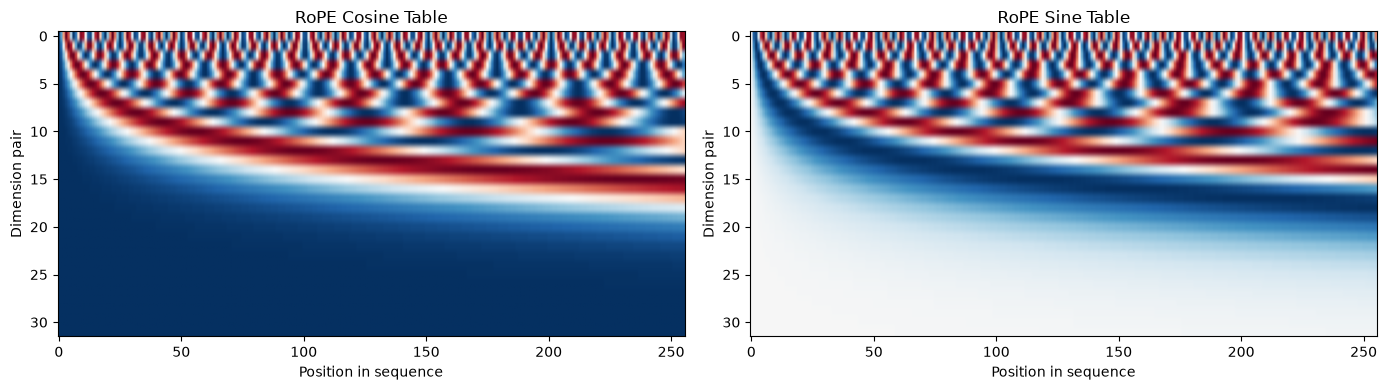

Low dimension pairs (top rows) -> fast oscillation -> short-range patterns
High dimension pairs (bottom rows) -> slow oscillations -> long-range patterns


In [8]:
# visualize the rotation frequencies
demo_cos, demo_sin = precompute_rope_freqs(head_dim=64, max_seq_len=256)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].imshow(demo_cos.T.numpy(), aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
axes[0].set_xlabel("Position in sequence")
axes[0].set_ylabel("Dimension pair")
axes[0].set_title("RoPE Cosine Table")

axes[1].imshow(demo_sin.T.numpy(), aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
axes[1].set_xlabel("Position in sequence")
axes[1].set_ylabel("Dimension pair")
axes[1].set_title("RoPE Sine Table")

plt.tight_layout()
plt.show()

print("Low dimension pairs (top rows) -> fast oscillation -> short-range patterns")
print("High dimension pairs (bottom rows) -> slow oscillations -> long-range patterns")

In [9]:
def repeat_kv(x, n_rep): 
    """
    Repeat KV heads to match the number of query heads. 
    x: [batch, n_kv_heads, seq_len, head_dim]
    Returns: [batch, n_kv_heads * n_rep, seq_len, head_dim]
    """
    if n_rep == 1: 
        return x
    b, n_kv, seq, hd = x.shape
    return (x[:, :, None, :, :]
            .expand(b, n_kv, n_rep, seq, hd)
            .reshape(b, n_kv * n_rep, seq, hd))

class GroupedQueryAttention(nn.Module): 
    """
    Grouped Query Attention with RoPE. 
    n_heads query heads, n_kv_heads key/value heads. 
    Groups of (n_heads // n_kv_heads) query heads share one KV pair.
    """
    def __init__(self, d_model, n_heads, n_kv_heads): 
        super().__init__()
        assert d_model % n_heads == 0
        assert n_heads % n_kv_heads == 0

        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.n_rep = n_heads // n_kv_heads
        self.head_dim = d_model // n_heads

        self.q_proj = nn.Linear(d_model, n_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.o_proj = nn.Linear(n_heads * self.head_dim, d_model, bias=False)

    def forward(self, x, rope_cos, rope_sin): 
        b, seq, _ = x.shape

        # Project Q, K, V
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # Reshape into heads
        q = q.view(b, seq, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(b, seq, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = v.view(b, seq, self.n_kv_heads, self.head_dim).transpose(1, 2)

        # Apply RoPE to Q and K (not v)
        q = apply_rope(q, rope_cos, rope_sin)
        k = apply_rope(k, rope_cos, rope_sin)

        # Repeat KV heads to match Q heads
        k = repeat_kv(k, self.n_rep)
        v = repeat_kv(v, self.n_rep)

        # Scaled dot-product attention with causal mask 
        scale = 1.0 / math.sqrt(self.head_dim)
        scores = (q @ k.transpose(-2, -1)) * scale

        mask = torch.triu(torch.ones(seq, seq, device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(mask, float("-inf"))

        weights = F.softmax(scores, dim=-1)

        # Dropout on attention weights (regularization)
        weights = F.dropout(weights, p=DROPOUT, training=self.training)

        out = weights @ v

        # Merge heads and project
        out = out.transpose(1, 2).contiguous().view(b, seq, -1)
        return self.o_proj(out)

In [10]:
print("GQA Shape Demo:")
print(f"  Config: d_model=256, n_heads=8, n_kv_heads=2")
print(f"  -> head_dim = 256/8  = 32")
print(f"  -> 8 Q heads, 2 KV heads")
print(f"  -> each KV head shared by 4 Q heads\n")

demo_gqa = GroupedQueryAttention(d_model=256, n_heads=8, n_kv_heads=2).to(device)
demo_cos, demo_sin = precompute_rope_freqs(head_dim=32, max_seq_len=128)
demo_cos, demo_sin = demo_cos.to(device), demo_sin.to(device)

demo_in = torch.randn(2, 16, 256, device=device)
demo_out = demo_gqa(demo_in, demo_cos, demo_sin)
print(f"   Input: {demo_in.shape}")
print(f"   Output: {demo_out.shape}")

q_params = 256 * (8 * 32)
kv_params = 256 * (2 * 32) * 2

print(f"\n Q projection params: {q_params:,} (full 8 heads)")
print(f"   KV projection params: {kv_params:,} (only 2 heads)")
print(f"   KV cache savings: {8/2}x smaller than standard MHA!")

GQA Shape Demo:
  Config: d_model=256, n_heads=8, n_kv_heads=2
  -> head_dim = 256/8  = 32
  -> 8 Q heads, 2 KV heads
  -> each KV head shared by 4 Q heads

   Input: torch.Size([2, 16, 256])
   Output: torch.Size([2, 16, 256])

 Q projection params: 65,536 (full 8 heads)
   KV projection params: 32,768 (only 2 heads)
   KV cache savings: 4.0x smaller than standard MHA!


In [11]:
class SwiGLU(nn.Module):
    """
    SwiGLU Feed-Forward Network.

    Two paths: 
        gate: SiLU(x @ W_gate) - controls flow
        up: x @ W_up           - carries information

        Combined: gate * up -> W_down

        SiLU(x) = x * sigmoid(x), a smooth version of ReLU.
    """
    def __init__(self, d_model, hidden_dim): 
        super().__init__()
        self.w_gate = nn.Linear(d_model, hidden_dim, bias=False)
        self.w_up   = nn.Linear(d_model, hidden_dim, bias=False)
        self.w_down = nn.Linear(hidden_dim, d_model, bias=False)
    
    def forward(self, x): 
        gate = F.silu(self.w_gate(x))
        up   = self.w_up(x)
        return F.dropout(self.w_down(gate * up), p=DROPOUT, training=self.training)

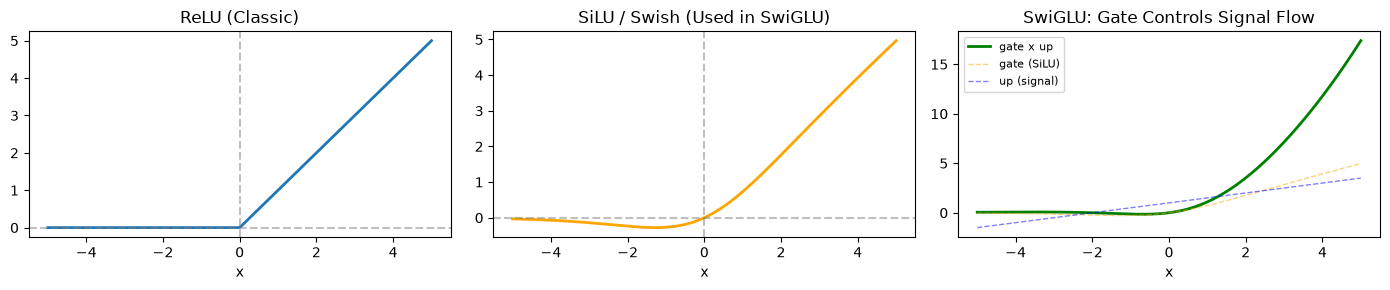

Key insight: SiLU is smooth unlike ReLU's hard cutoff at 0.
The gating mechanism lets the network LEARN which dimensions to keep.


In [12]:
# --- Demo: Compare activation functions ---
fig, axes = plt.subplots(1, 3, figsize=(14, 3))

x_range = torch.linspace(-5, 5, 200)

axes[0].plot(x_range, F.relu(x_range), linewidth=2)
axes[0].set_title("ReLU (Classic)")
axes[0].set_xlabel("x")
axes[0].axhline(y=0, color="gray", linestyle="--", alpha=0.5)
axes[0].axvline(x=0, color="gray", linestyle="--", alpha=0.5)

axes[1].plot(x_range, F.silu(x_range), linewidth=2, color="orange")
axes[1].set_title("SiLU / Swish (Used in SwiGLU)")
axes[1].set_xlabel("x")
axes[1].axhline(y=0, color="gray", linestyle="--", alpha=0.5)
axes[1].axvline(x=0, color="gray", linestyle="--", alpha=0.5)

gate_demo = F.silu(x_range)
up_demo = x_range * 0.5 + 1
axes[2].plot(x_range, gate_demo * up_demo, linewidth=2, color="green", label="gate x up")
axes[2].plot(x_range, gate_demo, linewidth=1, color="orange", alpha=0.5, linestyle="--", label="gate (SiLU)")
axes[2].plot(x_range, up_demo, linewidth=1, color="blue", alpha=0.5, linestyle="--", label="up (signal)")
axes[2].set_title("SwiGLU: Gate Controls Signal Flow")
axes[2].set_xlabel("x")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Key insight: SiLU is smooth unlike ReLU's hard cutoff at 0.")
print("The gating mechanism lets the network LEARN which dimensions to keep.")

In [13]:
class TransformerBlock(nn.Module): 
    """
    One layer of a modern transformer. 

    Pre-norm architecture: 
        x -> RMSNorm -> GQA Attention -> + residual
        x -> RMSNorm -> SwiGLU FFN    -> + residual
    """
    def __init__(self, d_model, n_heads, n_kv_heads, ffn_hidden_dim): 
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attention = GroupedQueryAttention(d_model, n_heads, n_kv_heads)
        self.ffn_norm  = RMSNorm(d_model)
        self.ffn       = SwiGLU(d_model, ffn_hidden_dim)

    def forward(self, x, rope_cos, rope_sin): 
        # Pre-norm -> Attention -> Residual
        x = x + self.attention(self.attn_norm(x), rope_cos, rope_sin)
        # Pre-norm -> FFN -> Residual
        x = x + self.ffn(self.ffn_norm(x))
        return x

In [14]:
class MiniLLM(nn.Module):
    """
    A small but modern language model.

    Architecture: modern transformer with all 4 upgrades.
    Training objective: next token prediction (BPE subwords).
    """
    def __init__(self, vocab_size, d_model, n_layers, n_heads, n_kv_heads, ffn_hidden_dim, max_seq_len):
        super().__init__()

        self.d_model = d_model
        self.max_seq_len = max_seq_len

        # Token embeddings
        self.token_emb = nn.Embedding(vocab_size, d_model)

        # Transformer blocks
        self.layers = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_heads, ffn_hidden_dim)
            for _ in range(n_layers)
        ])

        # Final norm and output head
        self.final_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

        # Weight tying: share embedding and lm_head weights
        self.lm_head.weight = self.token_emb.weight

        # Precompute RoPE frequencies
        head_dim = d_model // n_heads
        rope_cos, rope_sin = precompute_rope_freqs(head_dim, max_seq_len)
        self.register_buffer("rope_cos", rope_cos)
        self.register_buffer("rope_sin", rope_sin)

        # Initialize weights
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        b, seq_len = idx.shape

        # Token embedding
        x = self.token_emb(idx)

        # Pass through transformer blocks
        for layer in self.layers:
            x = layer(x, self.rope_cos, self.rope_sin)

        # Final norm + project to vocabulary
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                targets.view(-1)
            )

        return logits, loss


In [15]:
# model configuration 

config = {
    "vocab_size": vocab_size, 
    "d_model":    256, 
    "n_layers":   4, 
    "n_heads":    8, 
    "n_kv_heads": 2, 
    "ffn_hidden_dim": 680, 
    "max_seq_len":    256,
}

model = MiniLLM(**config).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 50)
print("  MODEL SUMMARY")
print("=" * 50)
print(f"  Vocabulary:      {config['vocab_size']}")
print(f"  Embedding dim:   {config['d_model']}")
print(f"  Layers:          {config['n_layers']}")
print(f"  Query heads:     {config['n_heads']}")
print(f"  KV heads:        {config['n_kv_heads']} (GQA ratio: {config['n_heads']//config['n_kv_heads']}:1)")
print(f"  FFN hidden dim:  {config['ffn_hidden_dim']}")
print(f"  Context length:  {config['max_seq_len']}")
print(f"  Head dim:        {config['d_model'] // config['n_heads']}")
print(f"{'=' * 50}")
print(f"  Total parameters:     {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Model size (approx):  {total_params * 4 / 1e6:.1f} MB (float32)")
print(f"{'=' * 50}")

  MODEL SUMMARY
  Vocabulary:      366
  Embedding dim:   256
  Layers:          4
  Query heads:     8
  KV heads:        2 (GQA ratio: 4:1)
  FFN hidden dim:  680
  Context length:  256
  Head dim:        32
  Total parameters:     2,840,320
  Trainable parameters: 2,840,320
  Model size (approx):  11.4 MB (float32)


In [16]:
# training hyperparameters
BATCH_SIZE = 64
CONTEXT_LEN = config["max_seq_len"]
LEARNING_RATE = 3e-4
MAX_STEPS = 3000
EVAL_INTERVAL = 250
EVAL_STEPS = 20
LOG_INTERVAL = 50

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

In [17]:
@torch.no_grad()
def estimate_loss():
    """Estimate loss on train and val splits."""
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(EVAL_STEPS):
            xb, yb = get_batch(split, BATCH_SIZE, CONTEXT_LEN)
            _, loss = model(xb, yb)
            losses.append(loss.item())
        out[split] = sum(losses) / len(losses)
    model.train()
    return out

In [ ]:
# Training loop
print("Starting training ....")
print(f"   {MAX_STEPS} steps, batch_size={BATCH_SIZE}, context_len={CONTEXT_LEN}")
print(f"   Evaluating every {EVAL_INTERVAL} steps")
print("-" * 60)

train_losses = []
val_losses = []
step_log = []
start_time = time.time()

model.train()
for step in range(MAX_STEPS):
    xb, yb = get_batch("train", BATCH_SIZE, CONTEXT_LEN)

    logits, loss = model(xb, yb)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    if step % LOG_INTERVAL == 0: 
        elapsed = time.time() - start_time
        print(f" Steps {step:5d}/{MAX_STEPS} | Loss: {loss.item():.4f} | Time: {elapsed:.0f}s")

    if step % EVAL_INTERVAL == 0 or step == MAX_STEPS - 1: 
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        step_log.append(step)
        if step > 0: 
            elapsed = time.time() - start_time
            steps_per_sec = step / elapsed
            remaining = (MAX_STEPS) / steps_per_sec
            print(f" >>> Eval @ step {step}: train={losses['train']:.4f}, val={losses['val']:.4f} | ~{remaining:.0f}s remaining")

total_time = time.time() - start_time
print("-" * 60)
print(f"Training complete! Total time: {total_time:.0f}s ({total_time/60:.1f} min)")
print(f"Final train loss: {train_losses[-1]:.4f}")
print(f"Final val loss:   {val_losses[-1]:.4f}")

Starting training ....
   3000 steps, batch_size=64, context_len=256
   Evaluating every 250 steps
------------------------------------------------------------
 Steps     0/3000 | Loss: 5.8529 | Time: 1s
 Steps    50/3000 | Loss: 3.8013 | Time: 23s
 Steps   100/3000 | Loss: 3.3059 | Time: 41s
 Steps   150/3000 | Loss: 3.0496 | Time: 60s
 Steps   200/3000 | Loss: 2.8452 | Time: 77s
 Steps   250/3000 | Loss: 2.7463 | Time: 93s
 >>> Eval @ step 250: train=2.6232, val=2.8855 | ~1176s remaining
 Steps   300/3000 | Loss: 2.5892 | Time: 114s
 Steps   350/3000 | Loss: 2.4926 | Time: 129s
 Steps   400/3000 | Loss: 2.3988 | Time: 144s
 Steps   450/3000 | Loss: 2.3307 | Time: 159s
 Steps   500/3000 | Loss: 2.3112 | Time: 174s
 >>> Eval @ step 500: train=2.2124, val=2.5459 | ~1068s remaining
 Steps   550/3000 | Loss: 2.2541 | Time: 192s
 Steps   600/3000 | Loss: 2.2052 | Time: 206s
 Steps   650/3000 | Loss: 2.1909 | Time: 220s
 Steps   700/3000 | Loss: 2.1584 | Time: 234s
 Steps   750/3000 | Loss:

In [ ]:
# --- Save Model & Tokenizer to Disk ---
checkpoint_path = "mini_llm_bpe_checkpoint.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "config": config,
    "merges": merges,
    "base_tokens": base_tokens,
    "token_to_id": token_to_id,
    "id_to_token": id_to_token,
}, checkpoint_path)

print(f"Model and tokenizer checkpoint saved to '{checkpoint_path}' ({os.path.getsize(checkpoint_path)/1e6:.1f} MB)")


In [ ]:
# --- Load Model from Disk Anytime (Without Retraining!) ---
checkpoint_path = "mini_llm_bpe_checkpoint.pt"

def load_checkpoint(checkpoint_path, device=device):
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"Checkpoint '{checkpoint_path}' not found! Train and save the model first.")
    ckpt = torch.load(checkpoint_path, map_location=device)
    loaded_model = MiniLLM(**ckpt["config"]).to(device)
    loaded_model.load_state_dict(ckpt["model_state_dict"])
    loaded_model.eval()
    print(f"Loaded checkpoint from '{checkpoint_path}' successfully!")
    return loaded_model, ckpt

# Example usage:
# loaded_model, ckpt = load_checkpoint(checkpoint_path)
# print(generate(loaded_model, 'ROMEO:', max_new_tokens=150, temperature=0.8))


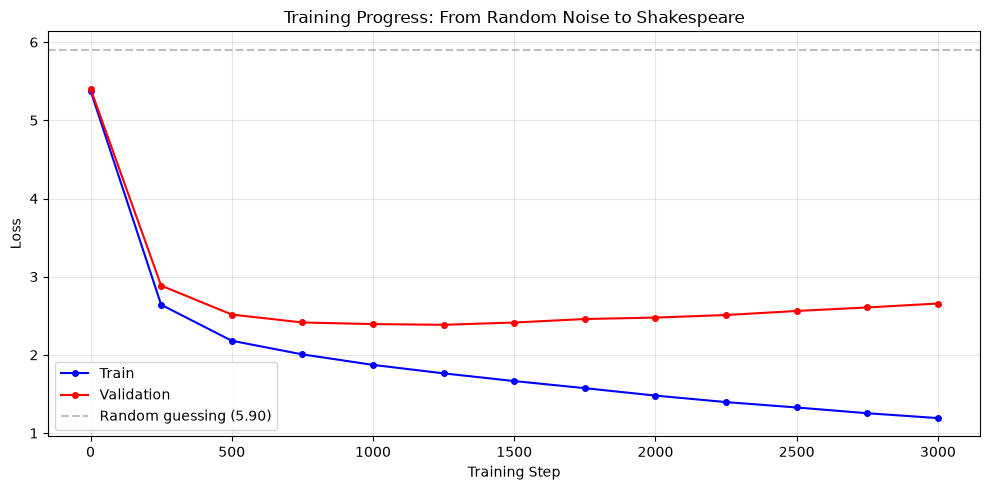

In [ ]:
# plot loss curve 
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(step_log, train_losses, "b-o", label="Train", markersize=4)
ax.plot(step_log, val_losses, "r-o", label="Validation", markersize=4)
ax.axhline(y=math.log(vocab_size), color="gray", linestyle="--", alpha=0.5,
            label=f"Random guessing ({math.log(vocab_size):.2f})")
ax.set_xlabel("Training Step")
ax.set_ylabel("Loss")
ax.set_title("Training Progress: From Random Noise to Shakespeare")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=250, temperature=0.8):
    """
    Generate text autoregressively using BPE tokenization.

    temperature controls randomness:
        low (0.3) -> conservative, repetitive
        mid (0.8) -> balanced
        high (1.2) -> creative, chaotic
    """
    model.eval()
    tokens = encode(prompt)
    if len(tokens) == 0:
        tokens = [0]
    tokens = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

    for _ in range(max_new_tokens):
        context = tokens[:, -config["max_seq_len"]:]
        logits, _ = model(context)
        logits = logits[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        tokens = torch.cat([tokens, next_token], dim=1)
    return decode(tokens[0].tolist())


In [ ]:
# --- Generate at different temperatures ---
prompt = "Hello:"

print("=" * 60)
print(f"   PROMPT: {prompt!r}")
print("=" * 60)

for temp in [0.5, 0.8, 1.0, 1.2]: 
    print(f"\n{'_' * 60}")
    print(f"  Temperature = {temp}")
    print(f"{'_' * 60}")
    output = generate(model, prompt, max_new_tokens=300, temperature=temp)
    print(output)

   PROMPT: 'ROMEO:'

____________________________________________________________
  Temperature = 0.5
____________________________________________________________
ROMEO:
There is a very pretty flowers of grief;
Which is some dangerous and every man.

BENVOLIO:
Tut, man, the windows of all the flowers of Mercutio.

MERCUTIO:
Nay, then, I pray thee, sir, of a man of a flower.
Come, sir, a pack to you.

BENVOLIO:
No, sir, hear me.

MERCUTIO:
No, sir, your general.

ROMEO:
Alas, poor soul, sir!

MERCUTIO:
Thou hast a traitor, take my leave of you; and sweet
to be a whore-hand; I know you not; Where's your
general is here of the point.

ROM

____________________________________________________________
  Temperature = 0.8
____________________________________________________________
ROMEO:
Swear to come, we'll not meet again.

BENVOLIO:
I will not sleep: we'll meet the matter.

ROMEO:
I pray, give me the sun that thou lovest her.

BENVOLIO:
Away, that is my master walls before the world;
If e

In [ ]:
# --- Try different prompts ---
prompts = [
    "ABHAY: PARV IS GAY",
    "PARV: YES"
]

for p in prompts: 
    print(f"\n{'=' * 60}")
    print(f"   PROMPT: {p!r}")
    print(f"{'=' * 60}")
    output = generate(model, p, max_new_tokens=200, temperature=0.8)
    print(output)


   PROMPT: 'ABHAY: PARV IS GAY'
ABHAY: PARV IS GAY:
No, beseech you, sir, pretty Oxford, thou art all.

GLOUCESTER:
To him what we came for this? For I have left them.

CLARENCE:
Alack, by your pates, the contempt of the city.

YORK:
We would you do 

   PROMPT: 'PARV: YES'
PARV: YESRCARDINE:
From one word, my lord, to give me my force:
If you'll hear my lordship's service to you.

ANGELO:
Go, go to you welcome, go with me and be it off!

ANGELO:

ANGELO:
He that I have been the 


In [ ]:
for name, param in model.named_parameters():
    print(f"{name:<35} | Shape: {str(list(param.shape)):<14} | Total numbers: {param.numel():,}")


token_emb.weight                    | Shape: [366, 256]     | Total numbers: 93,696
layers.0.attn_norm.weight           | Shape: [256]          | Total numbers: 256
layers.0.attention.q_proj.weight    | Shape: [256, 256]     | Total numbers: 65,536
layers.0.attention.k_proj.weight    | Shape: [64, 256]      | Total numbers: 16,384
layers.0.attention.v_proj.weight    | Shape: [64, 256]      | Total numbers: 16,384
layers.0.attention.o_proj.weight    | Shape: [256, 256]     | Total numbers: 65,536
layers.0.ffn_norm.weight            | Shape: [256]          | Total numbers: 256
layers.0.ffn.w_gate.weight          | Shape: [680, 256]     | Total numbers: 174,080
layers.0.ffn.w_up.weight            | Shape: [680, 256]     | Total numbers: 174,080
layers.0.ffn.w_down.weight          | Shape: [256, 680]     | Total numbers: 174,080
layers.1.attn_norm.weight           | Shape: [256]          | Total numbers: 256
layers.1.attention.q_proj.weight    | Shape: [256, 256]     | Total numbers: 65,53

In [ ]:
# Look at the first 3 BPE tokens and their first 4 embedding dimensions
print("token_emb.weight (first 3 rows, 4 columns):")
print(model.token_emb.weight[:, :])


token_emb.weight (first 3 rows, 4 columns):
tensor([[-0.0164, -0.0174,  0.1275,  ...,  0.0641, -0.0523,  0.0430],
        [ 0.0258, -0.0745, -0.0570,  ..., -0.0387,  0.0486, -0.0814],
        [ 0.0632, -0.0477, -0.0018,  ..., -0.0934,  0.0224, -0.0701],
        ...,
        [ 0.0364, -0.0521,  0.0167,  ..., -0.0033, -0.0071,  0.0289],
        [-0.0330,  0.1098, -0.0362,  ...,  0.0738, -0.0936, -0.1119],
        [-0.0012,  0.0672, -0.0063,  ...,  0.0385, -0.0465,  0.0065]],
       device='cuda:0', grad_fn=<AliasBackward0>)


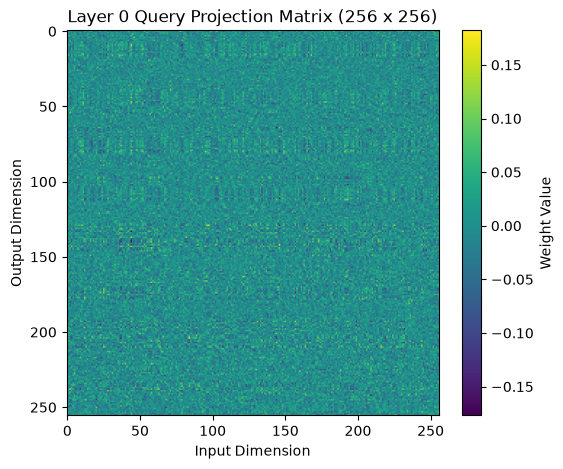

In [ ]:
import matplotlib.pyplot as plt

# Take the Query Projection matrix from Layer 0
weight_matrix = model.layers[0].attention.q_proj.weight.detach().cpu().numpy()

plt.figure(figsize=(6, 5))
plt.imshow(weight_matrix, cmap="viridis", aspect="auto")
plt.colorbar(label="Weight Value")
plt.title("Layer 0 Query Projection Matrix (256 x 256)")
plt.xlabel("Input Dimension")
plt.ylabel("Output Dimension")
plt.show()
